In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os,cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split
from keras.utils import np_utils

In [3]:
data_path='/content/drive/MyDrive/Rashi/rice_leaf_diseases' # Give your path here.
data_dir_list = ['0', '1', '2']
img_data_list=[]
labels = []

for dataset in data_dir_list:
    img_list=os.listdir(data_path+'/'+ dataset)
    print ('Loaded the images of dataset-'+'{}\n'.format(dataset))
    for img in img_list:
        input_img=cv2.imread(data_path + '/'+ dataset + '/'+ img )
        # input_img=cv2.IMREAD_GRAYSCALE
        labels.append(dataset)
        input_img_resize=cv2.resize(input_img,(128, 128))  # Here, Write your image size.
        img_data_list.append(input_img_resize)

label=np.array(labels)
data = np.array(img_data_list)
# print(data)
data = data.astype('float32')
data = data/255
data.shape

FileNotFoundError: ignored

In [ ]:
from skimage import io
from skimage.transform import rotate, AffineTransform, warp
import random
from skimage import img_as_ubyte
from skimage.util import random_noise
import numpy as np
def H(X, Y):
  R = []
  R_label = []
  for i in range(len(X)):
    R.append(X[i])
    R_label.append(Y[i])
  for i in range(len(X)):
    hflipped_image= np.fliplr(X[i])
    R.append(hflipped_image)
    R_label.append(Y[i])

  for i in range(len(X)):
    r_image = rotate(X[i], angle=5)
    R.append(r_image)
    R_label.append(Y[i])
  for i in range(len(X)):
    r_image1 = rotate(X[i], angle=-5)
    R.append(r_image1)
    R_label.append(Y[i])
  R = np.array(R)
  R_label  = np.array(R_label)
  return R, R_label

In [ ]:
data, label = H(data, label)

In [ ]:
num_classes = 3 # Number of classes in your dataset
Y = np_utils.to_categorical(label, num_classes)
x,y = shuffle(data,Y, random_state=2)
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size = 0.1, random_state = 2)
print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)

In [ ]:
y_test

In [4]:
X_train = X_train.reshape(-1,128,128, 3)
X_test = X_test.reshape(-1, 128, 128, 3)

NameError: ignored

In [ ]:
from keras.layers import Conv2D, GlobalAveragePooling2D, Reshape, Dense, Multiply, Add

def eca_module(input_tensor, gamma=2, b=1):
    channels = input_tensor.shape[-1]
    print(channels)

    squeeze = GlobalAveragePooling2D()(input_tensor)
    excitation = Dense(units=channels // gamma)(squeeze)
    excitation = Activation('relu')(excitation)
    excitation = Dense(units=channels)(excitation)
    excitation = Activation('sigmoid')(excitation)
    excitation = Reshape((1, 1, channels))(excitation)

    scale = Multiply()([input_tensor, excitation])

    output = Add()([scale, input_tensor])
    return output

In [ ]:
def residual_csa_module(input_tensor, reduction_ratio=16):
    channels = input_tensor.shape[-1]

    # Convolutional layer for feature extraction
    conv1 = Conv2D(filters=channels // reduction_ratio, kernel_size=(1, 1), padding='same', activation='relu')(input_tensor)
    conv2 = Conv2D(filters=channels // reduction_ratio, kernel_size=(1, 1), padding='same', activation='relu')(conv1)
    conv3 = Conv2D(filters=channels, kernel_size=(1, 1), padding='same', activation='relu')(conv2)

    # Spatial attention mechanism
    attention_map = Conv2D(filters=1, kernel_size=(1, 1), padding='same', activation='sigmoid')(conv3)

    # Multiply attention map with input tensor
    attention = Multiply()([attention_map, input_tensor])

    # Residual connection
    output = Add()([attention, input_tensor])

    return output

In [ ]:
from keras.layers import Conv2D, SeparableConv2D, Concatenate, AveragePooling2D

def inception_block(input_tensor, filters):
    # Path 1: 1x1 Convolution
    path1 = Conv2D(filters[0], kernel_size=(1, 1), padding='same', activation='relu')(input_tensor)

    # Path 2: 1x1 Convolution followed by 3x3 Depthwise Separable Convolution
    path2 = Conv2D(filters[1], kernel_size=(1, 1), padding='same', activation='relu')(input_tensor)
    path2 = SeparableConv2D(filters[2], kernel_size=(3, 3), padding='same', activation='relu')(path2)

    # Path 3: 1x1 Convolution followed by two 3x3 Depthwise Separable Convolutions
    path3 = Conv2D(filters[3], kernel_size=(1, 1), padding='same', activation='relu')(input_tensor)
    path3 = SeparableConv2D(filters[4], kernel_size=(3, 3), padding='same', activation='relu')(path3)
    path3 = SeparableConv2D(filters[5], kernel_size=(3, 3), padding='same', activation='relu')(path3)

    # Path 4: 3x3 Average Pooling followed by 1x1 Convolution
    path4 = AveragePooling2D(pool_size=(3, 3), strides=(1, 1), padding='same')(input_tensor)
    path4 = Conv2D(filters[6], kernel_size=(1, 1), padding='same', activation='relu')(path4)

    # Concatenate the paths
    output_tensor = Concatenate(axis=-1)([path1, path2, path3, path4])

    return output_tensor

In [ ]:
import keras
from keras.applications import EfficientNetB0, ResNet50, VGG16, InceptionV3
from keras.layers import Dense, GlobalAveragePooling2D, Conv2D, Flatten, Add, Activation, Input, MaxPooling2D
from keras.optimizers import RMSprop, Adam, SGD
from keras import regularizers
from keras.models import Model

# base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(128, 128, 3))
# for layer in base_model.layers:
#     layer.trainable = False

# x = base_model.output
input = Input((128, 128, 3))
x = Conv2D(filters=64, kernel_size=(3, 3), activation='relu')(input)
inception_block1 = inception_block(x, filters=[16, 32, 64, 32, 64, 128, 32])
x1 = Conv2D(filters=64, kernel_size=(3, 3), padding = 'same', activation='relu')(inception_block1)
x = Add()([x, x1])
x = Conv2D(filters=128, kernel_size=(3, 3), activation='relu')(x)
x = MaxPooling2D()(x)

# inception_block1 = inception_block(x, filters=[16, 32, 64, 32, 64, 128, 32])
# x = Conv2D(filters=256, kernel_size=(3, 3), activation='relu')(inception_block1)
# x = Conv2D(filters=128, kernel_size=(3, 3), activation='relu')(x)
# x = MaxPooling2D()(x)

eca_module1 = eca_module(x)
res_csa_module1 = residual_csa_module(x)

x = Add()([x, eca_module1, res_csa_module1])
x = Conv2D(filters=256, kernel_size=(3, 3), activation='relu')(x)

x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dense(128, activation='relu')(x)
# Add a fully connected layer for classification
output = Dense(3, activation='softmax')(x)

# Create the model
model = Model(inputs=input, outputs=output)

# Compile the model
# optimizer = Adam(learning_rate=0.0001, weight_decay = 0.99)
# sgd = SGD(learning_rate=0.001, momentum=0.9)
model.compile(optimizer= 'adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Print the model summary
model.summary()

128
Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 128, 128, 3  0           []                               
                                )]                                                                
                                                                                                  
 conv2d (Conv2D)                (None, 126, 126, 64  1792        ['input_1[0][0]']                
                                )                                                                 
                                                                                                  
 conv2d_3 (Conv2D)              (None, 126, 126, 32  2080        ['conv2d[0][0]']                 
                                )                                                         

In [ ]:
from keras.callbacks import EarlyStopping, ModelCheckpoint
early_stopping = EarlyStopping(
                              patience=20,
                              min_delta=0.001,
                              monitor="val_loss",
                              restore_best_weights=True
                              )
# Define the model checkpoint callback to save the best weights
checkpoint = ModelCheckpoint('/content/drive/MyDrive/Rashi/'+'-{epoch:02d}.h5', monitor='val_loss', save_best_only=True)

history = model.fit( X_train, y_train, batch_size = 16, epochs = 100,
                    validation_data = (X_test , y_test), callbacks=[early_stopping, checkpoint], verbose =1)

Epoch 1/100
27/27 [==============================] - 30s 160ms/step - loss: 1.1224 - accuracy: 0.3472 - val_loss: 1.1141 - val_accuracy: 0.1875
Epoch 2/100
27/27 [==============================] - 4s 143ms/step - loss: 1.0542 - accuracy: 0.4236 - val_loss: 1.0794 - val_accuracy: 0.3542
Epoch 3/100
27/27 [==============================] - 4s 137ms/step - loss: 0.9797 - accuracy: 0.5255 - val_loss: 1.3160 - val_accuracy: 0.2500
Epoch 4/100
27/27 [==============================] - 4s 143ms/step - loss: 0.8488 - accuracy: 0.6042 - val_loss: 0.8960 - val_accuracy: 0.5833
Epoch 5/100
27/27 [==============================] - 4s 136ms/step - loss: 0.7448 - accuracy: 0.6898 - val_loss: 0.9274 - val_accuracy: 0.5208
Epoch 6/100
27/27 [==============================] - 4s 137ms/step - loss: 0.7101 - accuracy: 0.6806 - val_loss: 1.0066 - val_accuracy: 0.5208
Epoch 7/100
27/27 [==============================] - 4s 145ms/step - loss: 0.7301 - accuracy: 0.6806 - val_loss: 0.8868 - val_accuracy: 0.645

<Figure size 640x480 with 0 Axes>

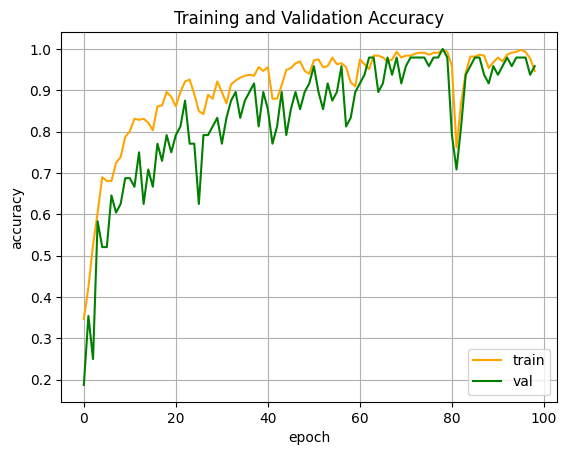

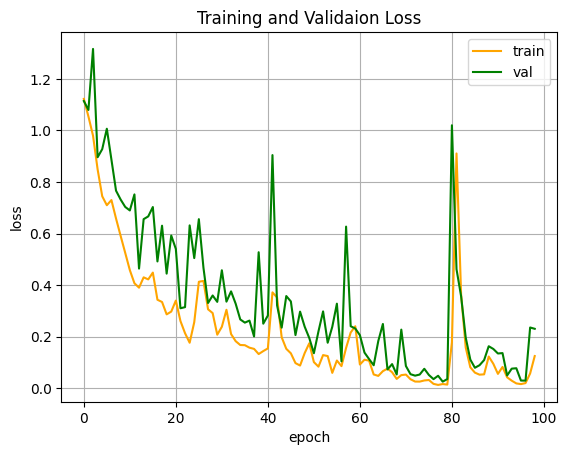

<Figure size 640x480 with 0 Axes>

In [ ]:
import matplotlib.image as mpimg
import matplotlib.pyplot as plt

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(acc))

plt.plot(epochs, acc, 'orange')
plt.plot(epochs, val_acc, 'g')
plt.title('Training and Validation Accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='lower right')
plt.grid()
plt.figure()

plt.plot(epochs, loss, 'orange')
plt.plot(epochs, val_loss, 'g')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper right')
plt.title('Training and Validaion Loss')
plt.grid()
plt.figure()

In [ ]:
from keras.models import load_model
model = load_model('/content/drive/MyDrive/Rashi/-77.h5')

In [ ]:
loss, accuracy = model.evaluate(X_test, y_test)
print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

2/2 [==============================] - 0s 62ms/step - loss: 0.0358 - accuracy: 0.9792
Test Loss: 0.03578205779194832
Test Accuracy: 0.9791666865348816


In [ ]:
# Predicting the Test set results
pred = model.predict(X_test)
print("Y_pred:", pred)
print("*****************")
y_pred = np.argmax(pred, axis = 1)
print("Y_pred:", y_pred)
print("*****************")
print("Y_test:", y_test)
y_true = np.argmax(y_test, axis = 1)
print("*****************")
print("Y_test:", y_true)

2/2 [==============================] - 0s 101ms/step
Y_pred: [[9.99999285e-01 7.02655882e-07 4.05531442e-10]
 [9.99506116e-01 4.93903819e-04 4.46757128e-12]
 [9.98645127e-01 1.35492859e-03 6.75418033e-09]
 [3.61511148e-36 5.24640064e-13 1.00000000e+00]
 [9.99992371e-01 7.58622173e-06 1.08316434e-09]
 [8.77556238e-29 4.84715964e-21 1.00000000e+00]
 [2.97221210e-04 9.98615026e-01 1.08775625e-03]
 [9.72740412e-01 2.72596106e-02 1.75752457e-09]
 [9.99998450e-01 1.60819150e-06 1.36814544e-11]
 [9.99897480e-01 1.02499835e-04 8.68218919e-09]
 [8.91250446e-02 9.10874963e-01 3.57159580e-10]
 [6.40816609e-07 9.99999285e-01 9.26122894e-08]
 [9.94025350e-01 5.97463502e-03 1.07936571e-09]
 [9.99999881e-01 1.25187668e-07 1.68822367e-09]
 [4.88303599e-11 8.97438824e-03 9.91025627e-01]
 [9.99911547e-01 8.83347457e-05 1.13774796e-07]
 [6.51835976e-03 9.93481636e-01 9.61966151e-09]
 [2.39757947e-09 9.97343004e-01 2.65695225e-03]
 [9.99999881e-01 1.39175640e-07 1.16857510e-10]
 [3.83360246e-27 4.56125565

In [ ]:
#Making the Confusion Matrix
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_true, y_pred)
target_names = ['bacterial_leaf_blight', 'brown_spot', 'leaf_smut']

Text(0.5, 23.38159722222222, 'Predicted label')

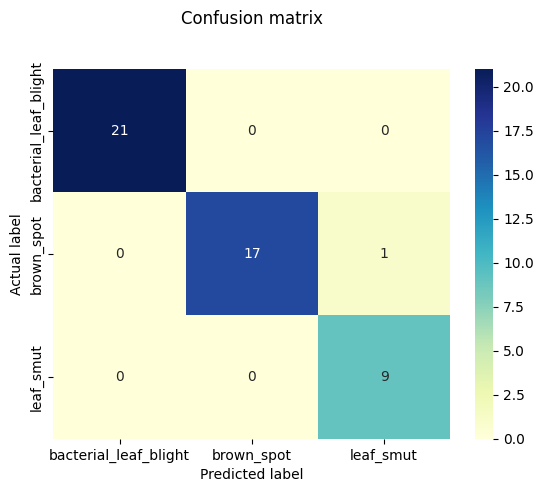

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
p = sns.heatmap(pd.DataFrame(cm), annot=True,xticklabels=target_names, yticklabels=target_names, cmap="YlGnBu" ,fmt='g')
plt.title('Confusion matrix', y=1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')

In [ ]:
#import classification_report
from sklearn.metrics import classification_report
print(classification_report(y_true,y_pred, target_names = target_names))

                       precision    recall  f1-score   support

bacterial_leaf_blight       1.00      1.00      1.00        21
           brown_spot       1.00      0.94      0.97        18
            leaf_smut       0.90      1.00      0.95         9

             accuracy                           0.98        48
            macro avg       0.97      0.98      0.97        48
         weighted avg       0.98      0.98      0.98        48



In [ ]:
from sklearn.metrics import roc_curve, auc
from itertools import cycle

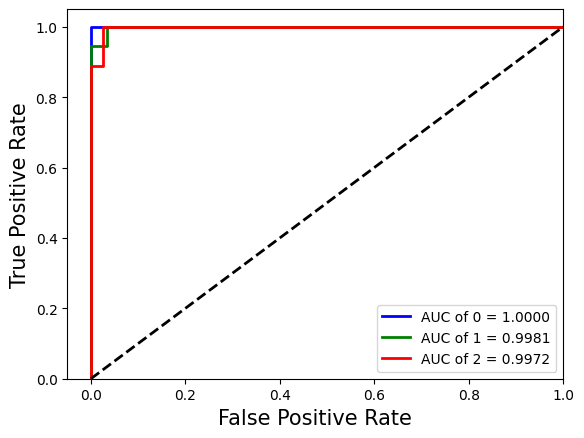

In [ ]:
fpr = dict()
tpr = dict()
roc_auc = dict()
lw=2
for i in range(3):
    fpr[i], tpr[i], _ = roc_curve(y_test[:, i], pred[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
colors =cycle(['blue', 'green', 'red'])
for i, color in zip(range(3), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label='AUC of {0} = {1:0.4f}'
             ''.format(i, roc_auc[i]))
plt.plot([0, 1], [0, 1], 'k--', lw=lw)
plt.xlim([-0.05, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate',fontsize=15)
plt.ylabel('True Positive Rate',fontsize=15)
# plt.title('Receiver operating characteristic for multi-class data')
plt.legend(loc="lower right")
plt.show()